In [1]:

import numpy as np
import joblib
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

X_train = np.load("../data/X_train.npy")
X_test = np.load("../data/X_test.npy")
y_train = np.load("../data/y_train.npy")
y_test = np.load("../data/y_test.npy")

X_train.shape, X_test.shape

((125973, 41), (22544, 41))

In [2]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

RandomForestClassifier(n_jobs=-1, random_state=42)

In [3]:
rf_preds = rf_model.predict(X_test)

print("Random Forest Results")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(y_test, rf_preds))
print("Recall:", recall_score(y_test, rf_preds))
print("F1 Score:", f1_score(y_test, rf_preds))
print("\nClassification Report:\n", classification_report(y_test, rf_preds))

Random Forest Results
Accuracy: 0.7731103619588361
Precision: 0.6610597140454163
Recall: 0.9712696941612604
F1 Score: 0.7866883523082697

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.62      0.76     12833
           1       0.66      0.97      0.79      9711

    accuracy                           0.77     22544
   macro avg       0.81      0.80      0.77     22544
weighted avg       0.83      0.77      0.77     22544



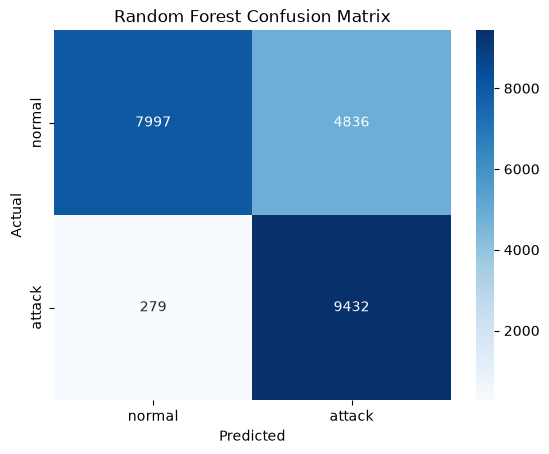

In [4]:
cm = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['normal','attack'], yticklabels=['normal','attack'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()

In [5]:
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm_model.fit(X_train, y_train)

SVC(random_state=42)

In [6]:
svm_preds = svm_model.predict(X_test)

print("SVM Results")
print("Accuracy:", accuracy_score(y_test, svm_preds))
print("Precision:", precision_score(y_test, svm_preds))
print("Recall:", recall_score(y_test, svm_preds))
print("F1 Score:", f1_score(y_test, svm_preds))
print("\nClassification Report:\n", classification_report(y_test, svm_preds))

SVM Results
Accuracy: 0.7819819020581973
Precision: 0.6686120095626494
Recall: 0.9791988466687261
F1 Score: 0.7946350227719049

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.63      0.77     12833
           1       0.67      0.98      0.79      9711

    accuracy                           0.78     22544
   macro avg       0.82      0.81      0.78     22544
weighted avg       0.84      0.78      0.78     22544



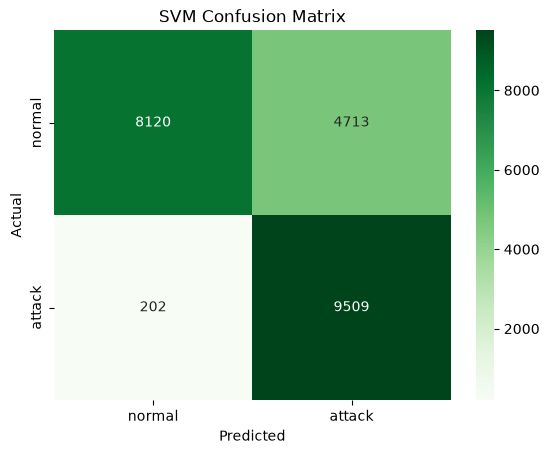

In [7]:
cm_svm = confusion_matrix(y_test, svm_preds)
sns.heatmap(cm_svm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['normal','attack'], yticklabels=['normal','attack'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.show()

In [8]:
results = {
    "Random Forest": f1_score(y_test, rf_preds, average="weighted"),
    "SVM": f1_score(y_test, svm_preds, average="weighted")
}
print(results)

# Save both models either way — you'll likely use RF for the dashboard (faster inference)
joblib.dump(rf_model, "../data/rf_model.pkl")
joblib.dump(svm_model, "../data/svm_model.pkl")
print("Models saved.")

{'Random Forest': np.float64(0.770179152426297), 'SVM': np.float64(0.7792838057434002)}
Models saved.
